# Experiments: which search heuristics help the course planner?

**Problem.** Pick one section for every course so that no two classes overlap. This is a CSP: the *variables* are the courses, the *domains* are their sections, and the *constraint* is "no time overlap".

**What we compare.** The same backtracking solver with different ideas switched on:

| Name | Idea in one line |
|---|---|
| brute force | try every combination (the baseline) |
| plain backtracking | choose a section for one course at a time, give up a branch as soon as there is a clash |
| + forward checking (FC) | after each choice, delete the clashing sections from the other courses; stop if some course has none left |
| + MRV | next, pick the course with the fewest sections left |
| + FC + MRV | both together |

**How to read the numbers.**
- **nodes** = how many section choices the search tried (smaller is better; for brute force it is the number of combinations checked).
- **backtracks** = how many times the search hit a dead end and had to go back.
- All methods must find the **same timetables**; the heuristics only change how much work is needed.

In [1]:
import os, sys
root = os.getcwd()                              # find the project folder (the one containing src/)
while not os.path.isdir(os.path.join(root, "src")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)
os.chdir(root); sys.path.insert(0, root)

import matplotlib.pyplot as plt
from src.loader import load_courses, load_preferences
from src.csp import build_csp, is_valid_schedule
from src.search import brute_force, solve

# the five methods we compare: name -> options passed to solve()  (None = brute force)
METHODS = {
    "brute force":        None,
    "plain backtracking": {},
    "+ FC":               {"use_fc": True},
    "+ MRV":              {"use_mrv": True},
    "+ FC + MRV":         {"use_fc": True, "use_mrv": True},
}

def run(csp, options):
    """Run one method. Returns (solutions, nodes, backtracks)."""
    if options is None:
        solutions, stats = brute_force(csp)
        return solutions, stats["combinations_checked"], None
    solutions, stats = solve(csp, **options)
    return solutions, stats["nodes"], stats["backtracks"]

def as_set(solutions):
    return {tuple(sorted((c, s.id) for c, s in a.items())) for a in solutions}

## Experiment 1: the starter catalog (the 6 courses used in the demo)

In [2]:
courses = load_courses("data/courses.json")
prefs = load_preferences("data/preferences.json")
csp = build_csp(courses, prefs["selected"])

print(f"{'method':<20}{'nodes':>8}{'backtracks':>12}{'timetables found':>18}")
reference = None
for name, options in METHODS.items():
    solutions, nodes, backtracks = run(csp, options)
    reference = reference or as_set(solutions)
    assert as_set(solutions) == reference and all(is_valid_schedule(s) for s in solutions)
    print(f"{name:<20}{nodes:>8}{str(backtracks):>12}{len(solutions):>18}")
print("\nEvery method found the same valid timetables.")

method                 nodes  backtracks  timetables found
brute force               32        None                 2
plain backtracking        20           5                 2
+ FC                      12           4                 2
+ MRV                     11           0                 2
+ FC + MRV                 7           0                 2

Every method found the same valid timetables.


## Experiment 2: a bigger, crowded catalog

`data/stress_catalog.json` has many courses whose sections often clash. "Size 8" means the first 8 courses of the file. Brute force is skipped at size 10 because it would have to check hundreds of thousands of combinations.

In [3]:
stress = load_courses("data/stress_catalog.json")
codes = list(stress)
sizes = [4, 6, 8, 10]
nodes_table = {name: {} for name in METHODS}
back_table  = {name: {} for name in METHODS}

for n in sizes:
    csp = build_csp(stress, codes[:n])
    reference = None
    for name, options in METHODS.items():
        if options is None and n == 10:
            continue                                  # brute force is too slow here
        solutions, nodes, backtracks = run(csp, options)
        reference = reference or as_set(solutions)
        assert as_set(solutions) == reference         # same answer as the reference
        nodes_table[name][n], back_table[name][n] = nodes, backtracks

def show(title, table):
    print(title)
    print(f"{'method':<20}" + "".join(f"{n:>10}" for n in sizes) + "   <- number of courses")
    for name, row in table.items():
        print(f"{name:<20}" + "".join(f"{str(row.get(n, '-')):>10}" for n in sizes))
    print()

show("Nodes (section choices tried):", nodes_table)
show("Backtracks (dead ends):", back_table)

Nodes (section choices tried):
method                       4         6         8        10   <- number of courses
brute force                256      4096     65536         -
plain backtracking         268      2908     20828     41308
+ FC                       222      2006     10879     13183
+ MRV                      260      2340     18036     20758
+ FC + MRV                 214      1806      8772      6186

Backtracks (dead ends):
method                       4         6         8        10   <- number of courses
brute force               None      None      None         -
plain backtracking           0         0       224      6796
+ FC                         0         0       137      1205
+ MRV                        0         0         0       372
+ FC + MRV                   0         0         0         0



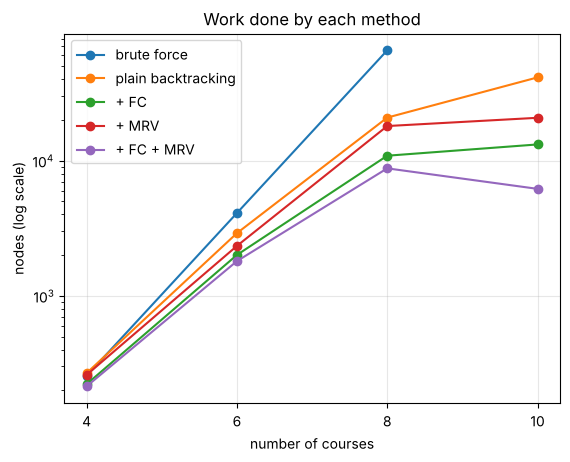

In [4]:
for name, row in nodes_table.items():
    plt.plot(list(row), list(row.values()), marker="o", label=name)
plt.yscale("log"); plt.xticks(sizes)
plt.xlabel("number of courses"); plt.ylabel("nodes (log scale)")
plt.title("Work done by each method"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## What we learned

1. **All methods give the same answer.** The heuristics make the search cheaper; they never change the result. We checked this against brute force, and every timetable was also checked by a separate validator.
2. **Brute force grows explosively** (256, 4,096, 65,536 combinations for 4, 6, 8 courses). Backtracking is already much cheaper because it abandons a branch at the first clash.
3. **Forward checking and MRV each help, and together they help most.** At 10 courses plain backtracking needs 41,308 nodes and 6,796 backtracks; FC + MRV needs 6,186 nodes and no backtracks at all.
4. **Why they work well together.** FC keeps the lists of remaining sections up to date, and MRV uses those lists to pick the most constrained course next, so a dead end is found early.
5. **On tiny problems nothing matters.** With 6 courses and 32 combinations every method is instant.

**Limits.** The catalogs are synthetic (invented sections), so the numbers show how the methods compare, not what a real semester looks like. The project also contains two extra ideas that are not compared here: LCV (try the least-constraining section first) and AC-3 (clean the section lists before searching). They are explained in the project report.